# EDA MovieLens-1M

Mục đích: hiểu dữ liệu để giải thích các lựa chọn về sau (shrinkage, CSR, chia tập). Chữ trên biểu đồ bằng tiếng Anh.

## 1. Đọc dữ liệu

TODO: dùng `src.data.load`, kiểm tra số dòng, số user, số phim, giá trị thiếu.

In [3]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.data import load

RAW_DIR = PROJECT_ROOT / "data" / "raw" / "ml-1m"
ratings = load.load_ratings(RAW_DIR)

n_rows = len(ratings)
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
missing_vals = ratings.isnull().sum()

print("=== DATASET OVERVIEW ===")
print(f"- Total ratings: {n_rows:,}")
print(f"- Total users: {n_users:,}")
print(f"- Total movies: {n_movies:,}")
print("\n=== MISSING VALUES ===")
print(missing_vals)

=== DATASET OVERVIEW ===
- Total ratings: 1,000,209
- Total users: 6,040
- Total movies: 3,706

=== MISSING VALUES ===
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64


## 2. Phân phối điểm

TODO: biểu đồ cột số đánh giá theo mức điểm, ghi giá trị trên cột.

/tmp/ipykernel_845/500959527.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="Blues_d")


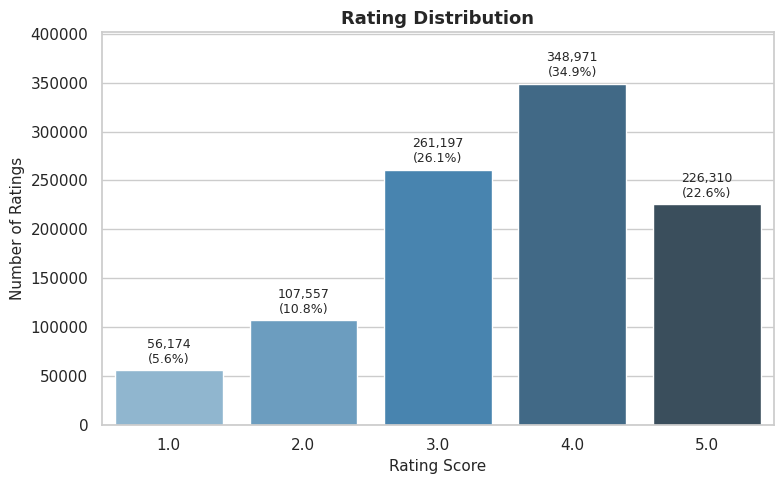

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.set_theme(style="whitegrid")

rating_counts = ratings["rating"].value_counts().sort_index()
ax = sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="Blues_d")

plt.title("Rating Distribution", fontsize=13, fontweight="bold")
plt.xlabel("Rating Score", fontsize=11)
plt.ylabel("Number of Ratings", fontsize=11)

total_ratings = len(ratings)
for p in ax.patches:
    height = int(p.get_height())
    pct = (height / total_ratings) * 100
    ax.annotate(
        f"{height:,}\n({pct:.1f}%)",
        (p.get_x() + p.get_width() / 2.0, height),
        ha="center",
        va="bottom",
        fontsize=9,
        xytext=(0, 3),
        textcoords="offset points",
    )

plt.ylim(0, max(rating_counts.values) * 1.15)
plt.tight_layout()
plt.show()

## 3. Phân phối đuôi dài của user và phim

TODO: số đánh giá mỗi user, mỗi phim. Rút ra lý do cần shrinkage và cần λ.

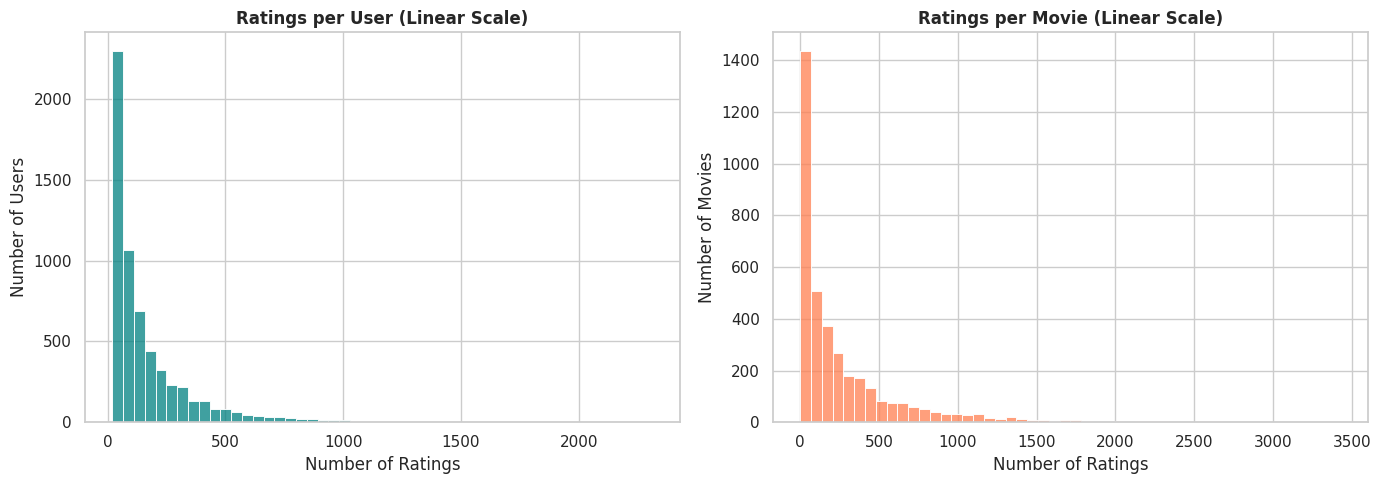

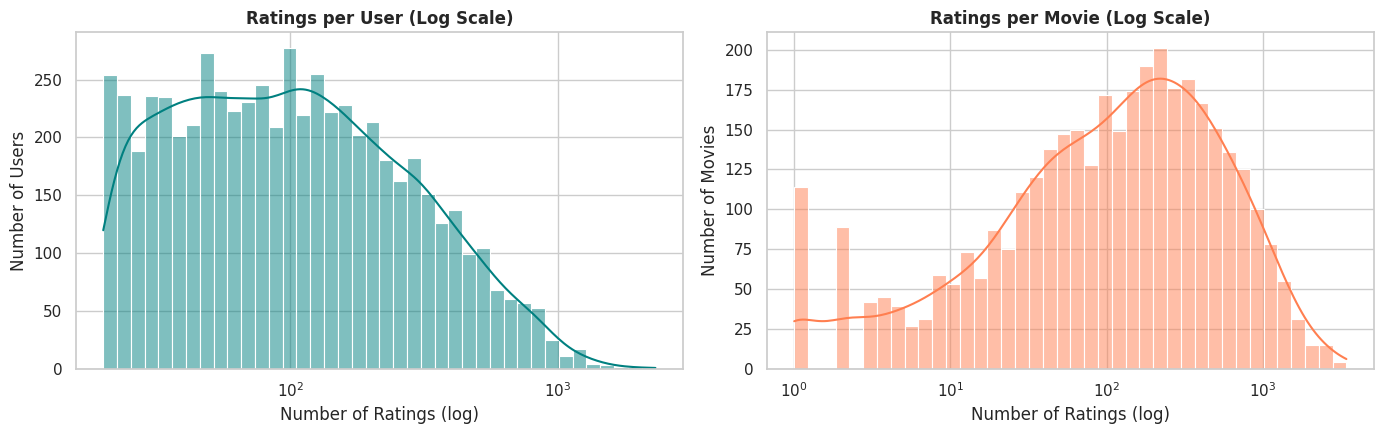

=== USER ACTIVITY QUANTILES ===
0.10     27.00
0.25     44.00
0.50     96.00
0.75    208.00
0.90    400.00
0.99    906.66
dtype: float64

=== MOVIE POPULARITY QUANTILES ===
0.10       7.0
0.25      33.0
0.50     123.5
0.75     350.0
0.90     729.5
0.99    1784.9
dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.set_theme(style="whitegrid")

user_counts = ratings.groupby("user_id").size()
sns.histplot(user_counts, bins=50, kde=False, ax=axes[0], color="teal")
axes[0].set_title("Ratings per User (Linear Scale)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Number of Ratings")
axes[0].set_ylabel("Number of Users")

movie_counts = ratings.groupby("movie_id").size()
sns.histplot(movie_counts, bins=50, kde=False, ax=axes[1], color="coral")
axes[1].set_title("Ratings per Movie (Linear Scale)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Number of Ratings")
axes[1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(user_counts, bins=40, kde=True, ax=axes[0], color="teal", log_scale=True)
axes[0].set_title("Ratings per User (Log Scale)", fontweight="bold")
axes[0].set_xlabel("Number of Ratings (log)")
axes[0].set_ylabel("Number of Users")

sns.histplot(movie_counts, bins=40, kde=True, ax=axes[1], color="coral", log_scale=True)
axes[1].set_title("Ratings per Movie (Log Scale)", fontweight="bold")
axes[1].set_xlabel("Number of Ratings (log)")
axes[1].set_ylabel("Number of Movies")

plt.tight_layout()
plt.show()

print("=== USER ACTIVITY QUANTILES ===")
print(user_counts.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))
print("\n=== MOVIE POPULARITY QUANTILES ===")
print(movie_counts.quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))

### Nhận xét phân phối đuôi dài và lý do cần Shrinkage, hệ số phạt lambda

**1. Phân phối đuôi dài (Long-tail):**

- **User:** Trung vị đạt 96 lượt đánh giá (25% ít nhất đánh giá từ 44 phim trở xuống; top 1% đánh giá hơn 906 phim).
- **Phim:** Trung vị đạt 123.5 lượt đánh giá (10% phim ít phổ biến nhất chỉ có từ 7 lượt trở xuống; top 1% có hơn 1,785 lượt).
- **Tác dụng của Log-scale:** Trên thang tuyến tính, đa số dữ liệu bị dồn sát trục tung do độ rộng cột cố định. Chuyển sang thang logarit giúp nén dải động theo cấp số nhân, đưa phân phối về dạng gần đối xứng quanh trung vị để dễ quan sát.

---

**2. Vì sao cần Shrinkage (tham số beta):**

- Các phim hoặc user ở vùng đuôi dài có số lượng tương tác rất nhỏ nên trung bình thô dễ bị nhiễu (ví dụ: một bộ phim chỉ có 1 lượt đánh giá 5 sao sẽ bị xếp điểm cao hơn cả những phim kinh điển có hàng nghìn lượt 4.5 sao).
- Shrinkage cộng thêm tham số làm mượt beta vào mẫu số: `b_hat = tổng(r - mu) / (số lượt đánh giá + beta)`.
- Khi số lượt đánh giá rất nhỏ so với beta, độ lệch tiến về 0, giúp kéo điểm ước lượng của các đối tượng ít dữ liệu về gần mức trung bình toàn cục mu (khoảng 3.58), loại bỏ sai lệch do cỡ mẫu nhỏ.

---

**3. Vì sao cần hệ số phạt Regularization (lambda):**

- Trong huấn luyện phân rã ma trận (Matrix Factorization), hàm mất mát được cộng thêm thành phần phạt L2: `Loss = tổng(r - r_hat)^2 + lambda * (||p||^2 + ||q||^2 + bu^2 + bi^2)`.
- Với các phim hoặc user ít tương tác, các vector đặc trưng ẩn rất dễ bị học vẹt (overfitting) theo vài điểm số cá biệt. Hệ số phạt lambda giúp ghìm độ lớn các vector này về gần 0 khi thiếu dữ liệu cập nhật, giúp mô hình tổng quát hóa tốt hơn trên tập kiểm thử.

## 4. Độ thưa và bộ nhớ

TODO: tính độ thưa, so sánh bộ nhớ dense và CSR bằng `src.data.sparse`.

In [6]:
import numpy as np
from src.data import sparse

shape = (n_users, n_movies)
total_possible = shape[0] * shape[1]
actual_interactions = len(ratings)
sparsity = (1.0 - (actual_interactions / total_possible)) * 100

print(f"Total possible interactions: {total_possible:,}")
print(f"Observed interactions: {actual_interactions:,}")
print(f"Matrix sparsity: {sparsity:.2f}%\n")

# Ánh xạ ID về chỉ số liên tục 0 -> N-1
user_codes = ratings["user_id"].astype("category").cat.codes.to_numpy()
item_codes = ratings["movie_id"].astype("category").cat.codes.to_numpy()
values = ratings["rating"].to_numpy()

csr_mat = sparse.build_csr(user_codes, item_codes, values, shape)

dense_bytes = sparse.dense_memory_bytes(shape)  # Mặc định float64
csr_bytes = sparse.csr_memory_bytes(csr_mat)

print("=== MEMORY COMPARISON (DENSE VS CSR) ===")
print(f"1. CSR Matrix memory: {csr_bytes / (1024 ** 2):.2f} MB")
print(f"2. Dense Matrix memory (float64): {dense_bytes / (1024 ** 2):.2f} MB")
print(f"=> CSR saves {dense_bytes / csr_bytes:.1f}x memory compared to Dense.")

Total possible interactions: 22,384,240
Observed interactions: 1,000,209
Matrix sparsity: 95.53%

=== MEMORY COMPARISON (DENSE VS CSR) ===
1. CSR Matrix memory: 11.47 MB
2. Dense Matrix memory (float64): 170.78 MB
=> CSR saves 14.9x memory compared to Dense.


## 5. Kết luận cho các bước sau

TODO: tóm tắt các nhận xét sẽ đưa vào báo cáo.


1. **Xử lý thiên kiến điểm số (Bias):** Dữ liệu lệch dương mạnh với 83.6% lượt đánh giá từ 3 sao trở lên (trung bình toàn cục khoảng 3.58). Mô hình cần tách riêng thành phần trung bình toàn cục và độ lệch cá nhân của user và phim trước khi học tương tác ẩn.

2. **Kiểm soát đuôi dài:** Áp dụng tham số làm mượt beta (shrinkage) cho mô hình cơ sở và tinh chỉnh hệ số phạt lambda trên tập validation cho các mô hình phân rã ma trận để tránh overfitting ở nhóm user/phim ít tương tác.

3. **Lưu trữ ma trận thưa (CSR):** Ma trận tương tác có độ thưa 95.53%. Lưu dạng CSR (`float64`) chỉ tốn 11.47 MB, tiết kiệm gấp 14.9 lần so với dạng Dense (170.78 MB) và tối ưu tốc độ truy xuất theo hàng cho thuật toán ALS.

4. **Chia tập dữ liệu (Train/Val/Test):** Do mọi user đều có tối thiểu 20 lượt đánh giá, có thể chia tập theo từng user mà không gặp tình trạng cold-start hoàn toàn ở tập kiểm thử.